*Note: This lab will be due after the exam, on October 14 @ midnight.*

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<img src="./src/Intraaortic_Balloon.png" width=600>

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

In [4]:
df = pd.read_csv('../data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


The point estimate of the ATE is $-.01$. According to the point estimate of the ATE, I would rather not get the intra aortic baloon pump because those who get it survive on a lower average rate. The ATE tells us the difference is around 1% between the two, so relatively speaking the difference is pretty small but it affirms the notion that pursuing conservative methods of reducing a heart attack lead to less deaths on average.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [5]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

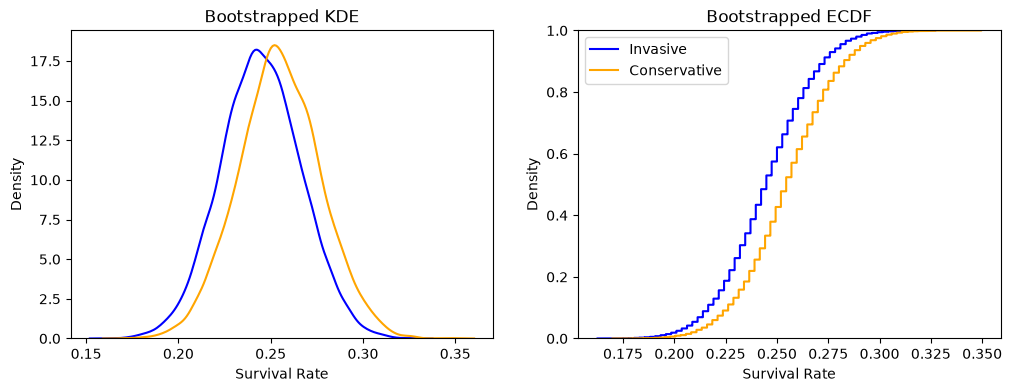

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

The bootstrapped KDEs and ECDFS both affirm the earlier statements regarding whether or not to choose conservative or progressive methods to lessen the risk of heart attack. We can see that the density concentration of survival rate for conservative methods lies at a higher value than the invasive methods. Generally speaking, this means that on average those who opt for more conservative methods survive on a higher average rate. The ECDF paints the same picture. The invasive method ECDF line being above the conservative line at all points means that for the proportion of patients, conservative methods always have a superior survival rate compared to invasive methods. 

**4.** Make a plot of the KDE and ECDF for the ATE. 

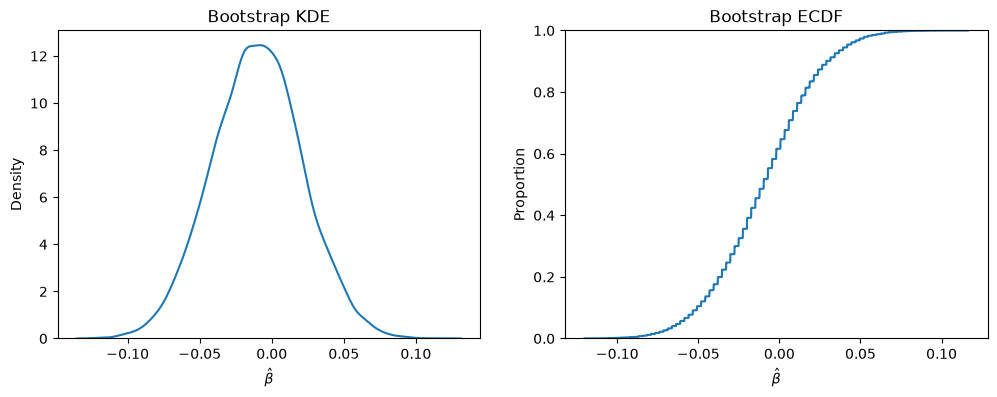

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [8]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06114674  0.04182711]
95% CI: [-0.07139639  0.05208322]
99% CI: [-0.08947076  0.07015755]


Zero is in the confidence intervals across all three significance levels. This means that we fail to reject the null hypothesis that the effect size is zero in all three cases because zero is included in each of the confidence intervals meaning the ATE is not statistically significant. 

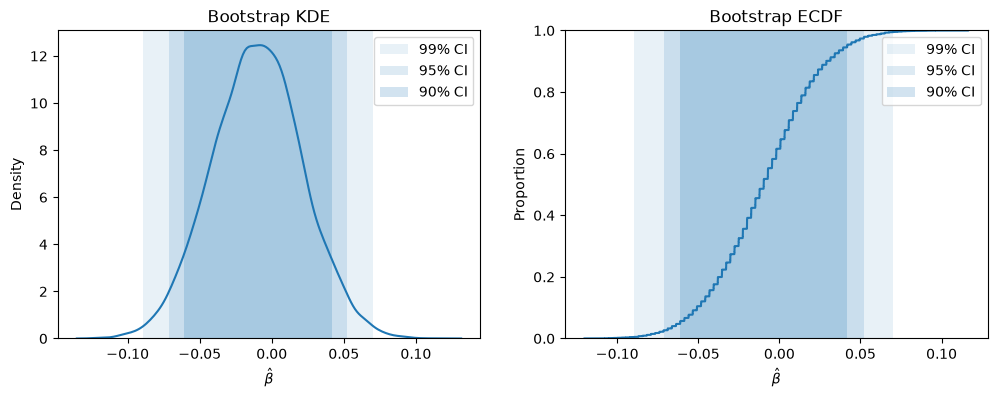

In [9]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

We have learned that inserting balloons into hearts is a nuanced and highly contentious medical practice that hasn't been unilateraly proven to have superiority over more conservative medical practices in lowering risk for heart attacks. We observed that the average treatment effect of our very limited data leans in favor of the more conservative methods with an average treatment effect of $.01$. However, our confidence intervals suggest that there is possibility for invasive medical practices, like putting balloons in hearts, to have a superior survival rates to more conservative methods due to the confidence interval extending into both *postive* and *negative*. However with the data currently at hand, it seems like a feasible assumption if my life was on the line to choose more conservative methods. This is due to not only the ATE, but also the $ \hat B$ KDEs and ECDF which posits that the highest density among the confidence intervals for the ATE is, in fact, negative meaning that conservative methods are superior to invasive methods at this point in time using this data.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

# 1. 

In [10]:
diabetes=pd.read_csv('../data/diabetes.csv')

for rows in diabetes['outcome']:
    if rows == 'success':
        diabetes['outcome'] = diabetes['outcome'].replace('success', 1)
    else:
        diabetes['outcome'] = diabetes['outcome'].replace('failure', 0)

pd.crosstab( diabetes['treatment'], diabetes['outcome'])

life = diabetes.loc[ diabetes['treatment'] == 'lifestyle', 'outcome'].mean()
met = diabetes.loc[ diabetes['treatment'] == 'met', 'outcome'].mean()
rosi = diabetes.loc[ diabetes['treatment'] == 'rosi', 'outcome'].mean()

print(f"Average success rates across treatments:\nLifestyle: {life:.3f}\nMetformin: {met:.3f}\nRosiglitazone: {rosi:.3f}")

Average success rates across treatments:
Lifestyle: 0.534
Metformin: 0.483
Rosiglitazone: 0.614


In [18]:
diabetes.shape

(699, 3)

# 2. 

In [23]:
## Bootstrapping:
R = 10_000

db_life = diabetes.loc[ diabetes['treatment'] == 'lifestyle',:]
db_met = diabetes.loc[ diabetes['treatment'] == 'met',:]
db_rosi = diabetes.loc[ diabetes['treatment'] == 'rosi',:]


outcome_a = []
outcome_b = []
outcome_c = []
ate_met_rosi = [] # Store computed effects
ate_life_met = []
ate_life_rosi = []

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = db_life.sample(frac=1.0, replace=True)
    df_bt = db_met.sample(frac=1.0, replace=True)
    df_ct = db_rosi.sample(frac=1.0, replace=True)

    life = df_at['outcome'].mean() # Mean outcome for lifestyle
    met = df_bt['outcome'].mean() # Mean outcome for metformin
    rosi= df_ct['outcome'].mean() # Mean outcome for 

    pre_met_rosi = met - rosi # 
    pre_life_met = life - met
    pre_life_rosi = life - rosi

    outcome_a.append(life) # Save new value
    outcome_b.append(met) # Save new value
    outcome_c.append(rosi) # Save new value
    
    ate_met_rosi.append(pre_met_rosi) 
    ate_life_met.append(pre_life_met)
    ate_life_rosi.append(pre_life_rosi)
    

# 3. 

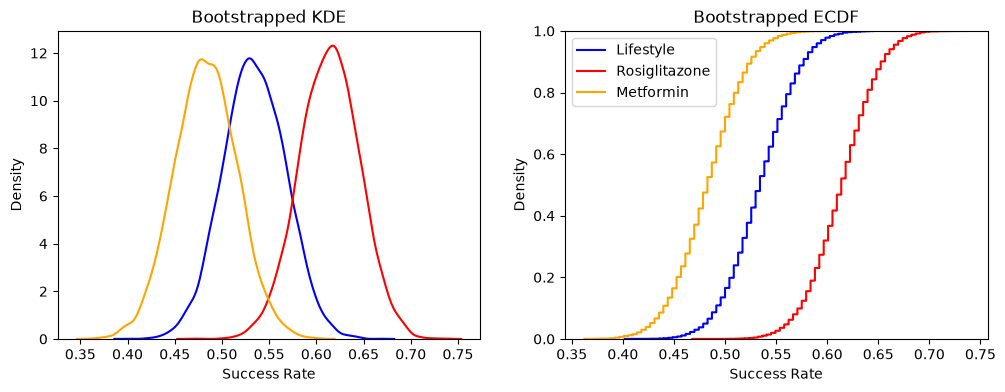

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_c, label='Rosiglitazone', color='red', ax=ax[0])
sns.kdeplot(outcome_b, label='Metformin', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_c, label='Rosiglitazone', color='red', ax=ax[1])
sns.ecdfplot(outcome_b, label='Metformin', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Density')

plt.legend()
plt.show()

We can see in the Boostrap KDEs and ECDFs plotted above there is a certain heirarchy of effectiveness when it comes to treatments. Metformin is the least successful treatment, having the lowest sucess density and proportion according to both the KDE and ECDF. The second best treatment is Lifestyle, having densities and proportions of success that lie in between Metformin and Rosiglitazone. The best treatment according to the data is Rosiglitazone, having the highest density and proportion of success among the three treatments.  

# 4.

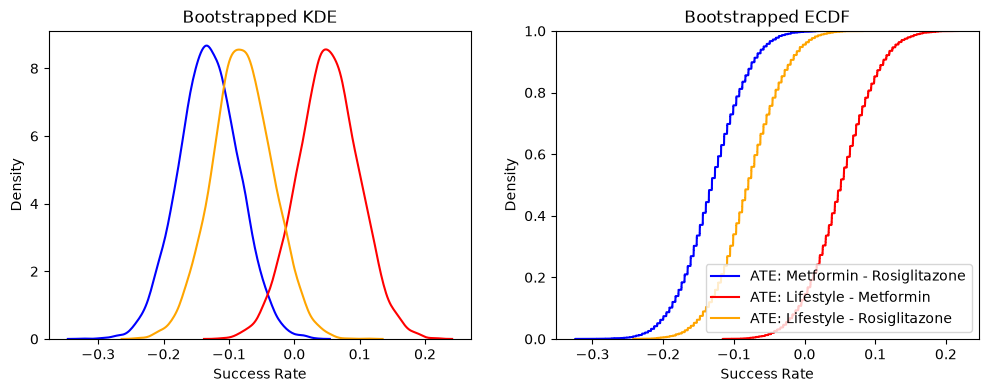

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ate_met_rosi, label='ATE: Metformin - Rosiglitazone', color='blue', ax=ax[0])
sns.kdeplot(ate_life_met, label='ATE: Lifestyle - Metformin', color='red', ax=ax[0])
sns.kdeplot(ate_life_rosi, label='ATE: Lifestyle - Rosiglitazone', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(ate_met_rosi, label='ATE: Metformin - Rosiglitazone', color='blue', ax=ax[1])
sns.ecdfplot(ate_life_met, label='ATE: Lifestyle - Metformin', color='red', ax=ax[1])
sns.ecdfplot(ate_life_rosi, label='ATE: Lifestyle - Rosiglitazone', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Density')

plt.legend()
plt.show()

# 5.

In [26]:
print("Confidence Intervals for ATE: Metformin - Rosiglitazone")
ci90 = np.quantile(ate_met_rosi, [.05, .95])
ci95 = np.quantile(ate_met_rosi, [.025, .975])
ci99 = np.quantile(ate_met_rosi, [.005, .995])
print(f"90% CI: [{ci90[0]:.4f}, {ci90[1]:.4f}]")
print(f"95% CI: [{ci95[0]:.4f}, {ci95[1]:.4f}]")
print(f"99% CI: [{ci99[0]:.4f}, {ci99[1]:.4f}]")

Confidence Intervals for ATE: Metformin - Rosiglitazone
90% CI: [-0.2083, -0.0537]
95% CI: [-0.2212, -0.0406]
99% CI: [-0.2472, -0.0105]


In [27]:
print("Confidence Intervals for ATE: Lifestyle - Rosiglitazone")
ci90 = np.quantile(ate_life_rosi, [.05, .95])
ci95 = np.quantile(ate_life_rosi, [.025, .975])
ci99 = np.quantile(ate_life_rosi, [.005, .995])
print(f"90% CI: [{ci90[0]:.4f}, {ci90[1]:.4f}]")
print(f"95% CI: [{ci95[0]:.4f}, {ci95[1]:.4f}]")
print(f"99% CI: [{ci99[0]:.4f}, {ci99[1]:.4f}]")

Confidence Intervals for ATE: Lifestyle - Rosiglitazone
90% CI: [-0.1565, -0.0025]
95% CI: [-0.1695, 0.0104]
99% CI: [-0.1994, 0.0403]


In [28]:
print("Confidence Intervals for ATE: Lifestyle - Metformin")
ci90 = np.quantile(ate_life_met, [.05, .95])
ci95 = np.quantile(ate_life_met, [.025, .975])
ci99 = np.quantile(ate_life_met, [.005, .995])
print(f"90% CI: [{ci90[0]:.4f}, {ci90[1]:.4f}]")
print(f"95% CI: [{ci95[0]:.4f}, {ci95[1]:.4f}]")
print(f"99% CI: [{ci99[0]:.4f}, {ci99[1]:.4f}]")

Confidence Intervals for ATE: Lifestyle - Metformin
90% CI: [-0.0259, 0.1286]
95% CI: [-0.0428, 0.1454]
99% CI: [-0.0690, 0.1718]


With the null hypothesis of $H_0: \text{ATE} = 0$, the Following ATE's are statistically significant:

ATE: Metformin - Rosiglitazone:

**Statistically Significant at all three levels**

ATE: Lifestyle - Rosiglitazone

**Statistically Significant at the .1 level.**

ATE: Lifestyle - Metformin

**Not statistically significant**



This means that in terms of effectiveness, Rosiglitazone is superior to the others, but is close in effect to Lifestyle treatments. This is because in the ATE: Metformin - Rosiglitazone there is statistical significance across all three levels , meaning that Rosiglitazone is superior at preventing diabetes progression than metformin because the bounds of the confidence interval are strictly negative. In the Confidence Intervals for ATE: Lifestyle - Rosiglitazone, there is statistical significance at the .1 level, but not at the .05 and .01 levels. This means that at the .01 level, Rosiglitazone is better than Lifestyle treaments because the bounds are strictly negative, but at the .05 and .01 there is not enough evidence to conclude that there is a difference in treatments. Taking in everything this far and the evidence from the confidence intervals for average treatment effects, Metformin appears to be a poor treatment for preventing progression to diabetes compared to the two other treatments.



# 6.

**View Separate Doc in Github Repo.**